Lab 4 - Ella Haynes

In [1]:
# importing necessary packages

#%matplotlib inline
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import scipy
from scipy import stats
import h5py

In [2]:
# opening the file as read-only
hf = h5py.File('/home/jovyan/Shared/gammaray_lab4.h5', 'r')

# looking at the header
hf.keys()

<KeysViewHDF5 ['data']>

In [3]:
# importing data into an array
data = np.array(hf.get('data'), dtype = 'float')

# checking data is as expected
np.shape(data)
data[:,0]

array([9.40680016e+08, 3.15000000e+02, 4.50000000e+01, 1.00000000e+01])

Question 1 - Examine the data. Give a high level description of the data features you see. Specifically comment on whether you see signal contamination in your data, and how you plan to build a background pdf().

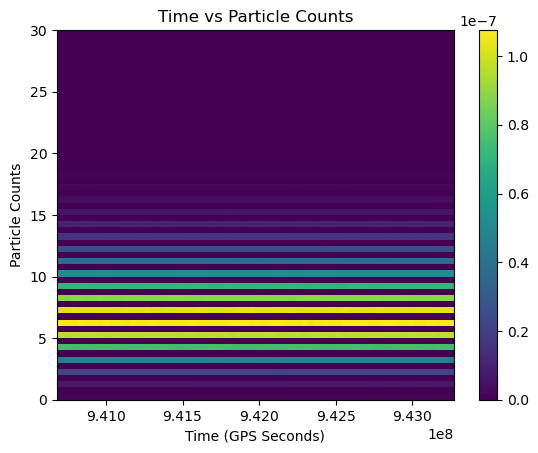

In [4]:
# plotting the time vs particle counts
fig, ax = plt.subplots(1, 1)
plt.xlabel('Time (GPS Seconds)')
plt.ylabel('Particle Counts')
plt.title('Time vs Particle Counts')
plt.hist2d(data[0], data[3], bins = 60, density = True)
plt.colorbar()

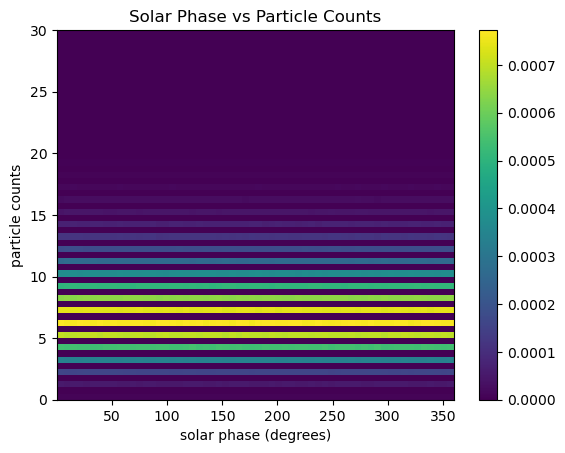

In [5]:
# plotting the solar phase vs particle counts
fig, ax = plt.subplots(1, 1)
plt.xlabel('solar phase (degrees)')
plt.ylabel('particle counts')
plt.title('Solar Phase vs Particle Counts')
plt.hist2d(data[1], data[3], bins = 60, density = True)
plt.colorbar()

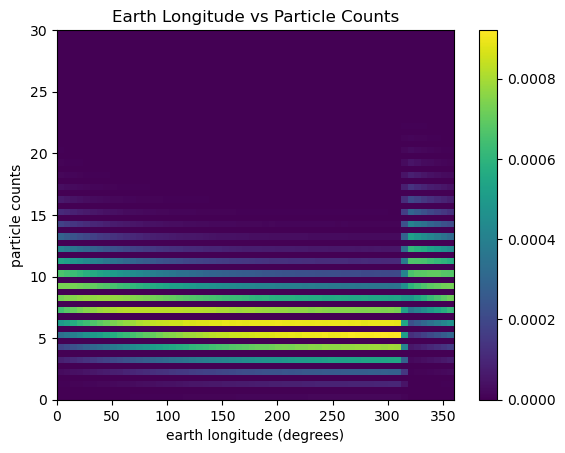

In [6]:
# plotting the earth longitude vs particle counts
fig, ax = plt.subplots(1, 1)
plt.hist2d(data[2], data[3], bins = 60, density = True)
plt.xlabel('earth longitude (degrees)')
plt.ylabel('particle counts')
plt.title('Earth Longitude vs Particle Counts')
plt.colorbar()

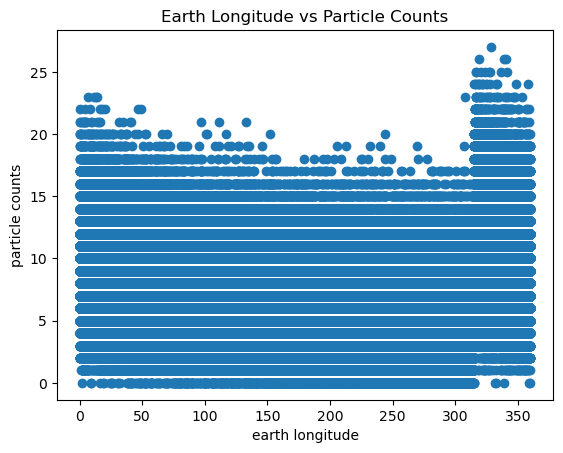

In [7]:
# plot of earth longitude vs particle counts to further evaluate the unusual break in the lines above
fig, ax = plt.subplots(1, 1)
plt.xlabel('earth longitude')
plt.ylabel('particle counts')
plt.title('Earth Longitude vs Particle Counts')
ax.scatter(data[2][:1000000], data[3][:1000000])
plt.show()

From the above plots, we can see that gamma ray particle counts are fairly consistent (visible via the straight, matching lines on the 2D histograms for time and solar phase). However, we notice something unusual when plotting particle counts and Earth longitude: a spike in counts around ~320 degrees. This spike is visible by an offset in the 2D histogram and a jump in the scatter plot, both at ~320 degrees. I believe this change in counts is a sign of signal contamination that needs to be further investigated. 

Given this data, I plan to build a background PDF under the assumption it is a Poisson distribution because it must be non-negative, discrete, and periodic (i.e. a certain number of counts in a given interval).

Question 2 - The background is not consistent across the dataset. Find and describe as accurately as you can how the background changes.

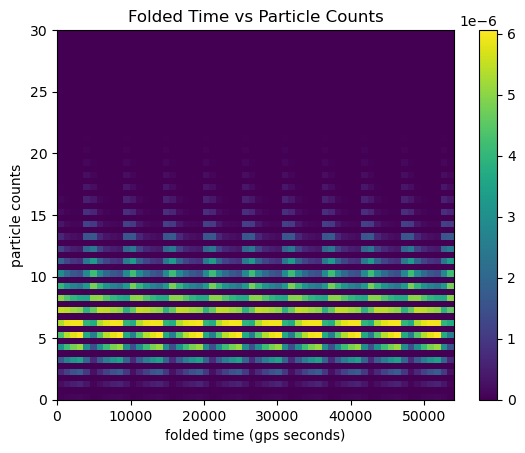

In [8]:
# 90 minute orbit and 100 millisecond interval of detection -> 54000 intervals
num_of_int = 90 * 60 * 1000 / 100

# plotting time % 54000 vs particle count
fig, ax = plt.subplots(1, 1)
plt.xlabel('folded time (gps seconds)')
plt.ylabel('particle counts')
plt.title('Folded Time vs Particle Counts')
plt.hist2d(data[0] % num_of_int, data[3], bins = 60, density = True)
plt.colorbar()

From this plot, we can observe that the background data is in fact not consistent, but rather it is periodic. The background sharply increases every ~5000 gps seconds, and then decays seemingly (based on visual cues) exponentially until it jumps yet again. 

Question 3 - Create a model for the background that includes time dependence, and explicitly compare your model to the data. How good is your model of the background?

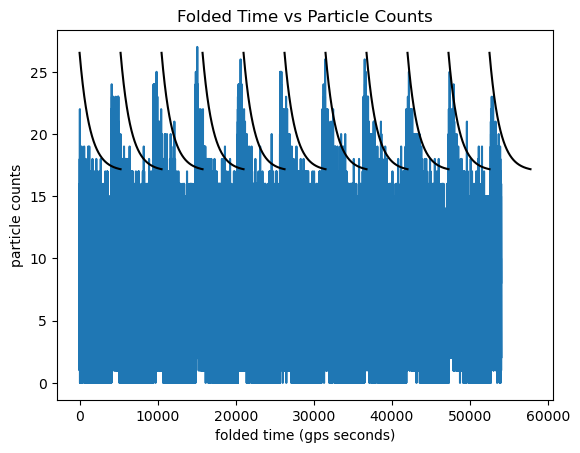

In [48]:
# plotting time % 54000 vs particle count
num_of_int = 90 * 60 * 1000 / 100
fig, ax = plt.subplots(1, 1)
plt.xlabel('folded time (gps seconds)')
plt.ylabel('particle counts')
plt.title('Folded Time vs Particle Counts')
plt.plot(data[0][:1000000] % num_of_int, data[3][:1000000])

# plotting the periodic exponential decays as my model (values are estimated based on visual observation)
approx_width = 5250
approx_peaks = [np.arange(0, 55000, approx_width)]
for peak in approx_peaks:
    stdeva = (peak + approx_width - peak) / 4
    x = np.linspace(peak, peak + approx_width, 1000)
    ax.plot(x, (stats.expon.pdf(x, loc = peak, scale = stdeva) * 25 * 500) + 17, color = 'black')
plt.show()

Above, I plotted the first 1 million data points of folded time (in gps seconds) vs particle counts, and overlayed a repeating (periodic) exponential decay based on the visual observation of the 2D histogram to evaluate the accuracy of my periodic exponential model. My findings are that the exponential decay roughly matches the data. Notably, sorting out the correct location and scale of the peaks creates most of the observable errors, as well as it is important to remember this is 1/25 of the data (selected because it was the maximum number my computer is able to run without Jupyter Hub crashing), thus the pattern of the peaks will be slightly less defined than when running the entire dataset. In conclusion, the model roughly matches the data, and computer and human error prevent the model from getting closer to the data.

Question 4 - Because the background varies, your discovery sensitivity threshold (how many particles you would need to see) also varies. What is the '5-sigma' threshold for a 100 millisecond GRB at different times?

Because the model is roughly accurate, I will be using it to calculate the 5 sigma:

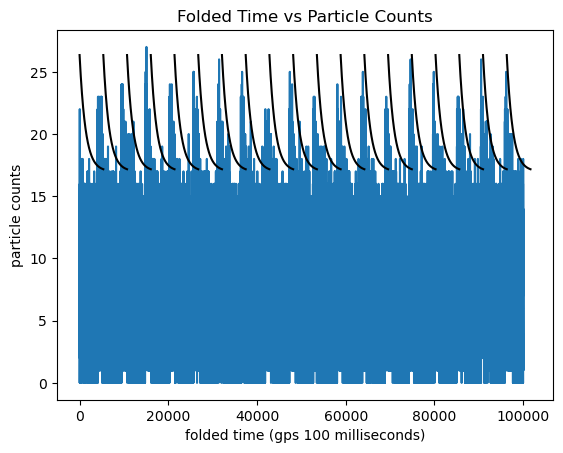

In [59]:
# plotting time % (54000 / 0.1) vs particle count (0.1 because that way we are mapping every 100 milliseconds)
num_of_int = 90 * 60 * 1000 / 0.1 / 100
fig, ax = plt.subplots(1, 1)
plt.xlabel('folded time (gps 100 milliseconds)')
plt.ylabel('particle counts')
plt.title('Folded Time vs Particle Counts')
plt.plot(data[0][:1000000] % num_of_int, data[3][:1000000])

# plotting the periodic exponential decays as my model (values are estimated based on visual observation)
approx_width = 5350
approx_peaks = [np.arange(0, 100000, approx_width)]
for peak in approx_peaks:
    stdeva = (peak + approx_width - peak) / 4
    x = np.linspace(peak, peak + approx_width, 1000)
    ax.plot(x, (stats.expon.pdf(x, loc = peak, scale = stdeva) * 25 * 500) + 17, color = 'black')
plt.show()

In [71]:
# calculating 5 sigma for the 1st exponential distribution
diffs = [0, 1000, 3000, 4000]
peak = 0
for diff in diffs :
    stdeva = np.mean((stats.expon.pdf(x, loc = peak + diff, scale = stdeva) * 25 * 500) + 17)
    five_sigma = 5 * stdeva
    print(f'The 5 sigma at {peak + diff} 100 milliseconds is {five_sigma}.')

# calculating 5 sigma for the 2nd exponential distribution
diffs = [0, 1000, 3000, 4000]
peak = 5350
for diff in diffs :
    stdeva = np.mean((stats.expon.pdf(x, loc = peak + diff, scale = stdeva) * 25 * 500) + 17)
    five_sigma = peak + (5 * stdeva)
    print(f'The 5 sigma at {peak + diff} 100 milliseconds is {five_sigma}.')

The 5 sigma at 0 100 milliseconds is 85.71519191020573.
The 5 sigma at 1000 100 milliseconds is 85.65711036950098.
The 5 sigma at 3000 100 milliseconds is 85.55471027813377.
The 5 sigma at 4000 100 milliseconds is 85.6967812800538.
The 5 sigma at 5350 100 milliseconds is 5435.907117069767.
The 5 sigma at 6350 100 milliseconds is 5435.657017273893.
The 5 sigma at 8350 100 milliseconds is 5435.554710214227.
The 5 sigma at 9350 100 milliseconds is 5435.696781280118.


I honestly really struggled with understanding this question, but my end interpretation is that I should fold the time so that the values are in 100 millisecond intervals and then calculate the 5 sigma as one moves across the periodic exponential model. I selected values smaller than the width of one exponential decay as the above values will repeat when moving to the same place on a new exponential decay, thus traversing the same epxonential decay is far more interesting. Here, we can see slight fluctuations in the 5 sigma value.

Question 5 - While this is simulated data, it is based on a real effect seen by low Earth orbit satellites. Can you identify the cause of the variable background and propose a physical model?

I believe the variable background is caused by the satellite orbiting Earth and going behind our planet (relative to the sun) periodically. The sun emits gamma rays, thus different levels of sun exposure would change the number of gamma rays recorded. To mitigate this problem (via a physical model), I propose a few possible solutions: (1) adjusting the results by the background pattern, or (2) recording data when the satellite is in a small, relatively unchanged (in terms of the background) range of orbit. (1) Given the background pattern, it can be 'subtracted' from the collected data to leave a clean results in which new patterns can be accurately interpreted. (2) If the background remains relatively unchanged for a stretch of its orbit, data can be gathered from just that time and be relatively 'clean'.